In [1]:
from specml.data import SpectroscopicData
from specml.visualization import plotting
from specml.processing.masking import create_mask_from_area, apply_mask, rebuild_tissue_mask
from specml.processing.preprocessing import vector_norm, adjust_spectra_min_to_zero
import numpy as np

In [2]:
test_data = SpectroscopicData(file_path=f'E:/Lung_Data_8cm/6F-6504-01/6F-6504-01_top2/6f-6504-01_top2.dmt', inplace=True)
test_data.easy_preprocess(area_threshold=4.5)

INFO:specml.data.loaders:Data loaded from E:/Lung_Data_8cm/6F-6504-01/6F-6504-01_top2/6f-6504-01_top2.dmt with shape (512, 1664, 754)
INFO:specml.data.spectroscopic_data:Data flattened and mask applied. Shape of processed data: (851968, 754)
INFO:specml.data.spectroscopic_data:{'filename': 'E:/Lung_Data_8cm/6F-6504-01/6F-6504-01_top2/6f-6504-01_top2.dmt', 'xpixels': 1664, 'ypixels': 512, 'xtiles': 13, 'ytiles': 4, 'numpts': 754, 'fpasize': 128, 'original_shape': (512, 1664, 754)}
INFO:specml.data.spectroscopic_data:Kept wavenumber range from 950 to 3550
INFO:specml.data.spectroscopic_data:Removed wavenumber range from 1350 to 1490
INFO:specml.data.spectroscopic_data:Removed wavenumber range from 2300 to 2400
INFO:specml.data.spectroscopic_data:Removed wavenumber range from 2700 to 3000
INFO:specml.data.spectroscopic_data:Removed wavenumber range from 2250 to 2450
INFO:specml.data.spectroscopic_data:Kept wavenumber range from 1000 to 1800


In [3]:
from specml.ml_models.clustering import KMeansClustering, SpectralClusteringAlgorithm, AgglomerativeClusteringAlgorithm
from specml.feature_engineering.dim_reduction import apply_pca
pca_res = apply_pca(test_data, n_components=3)
k_means = SpectralClusteringAlgorithm()
res = pca_res.cluster_data(k_means)

c:\Users\u37314kd\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


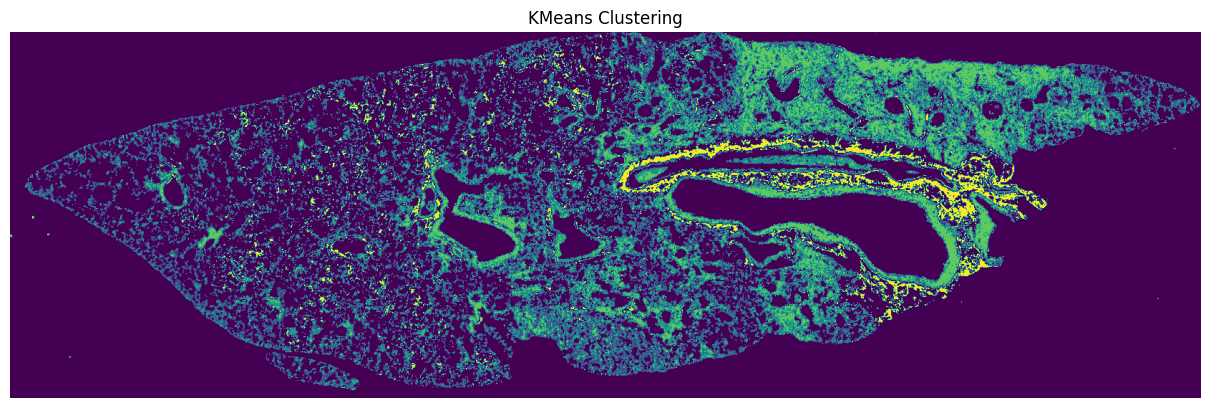

In [4]:
from specml.visualization.plotting import display_image

r = display_image(res.cluster_labels, res.original_shape[0], res.original_shape[1], res.mask, title='KMeans Clustering')

In [11]:
pca_res2 = apply_pca(test_data, n_components=2)
k_means2 = AgglomerativeClusteringAlgorithm()
print(pca_res2.reduced_data.shape)
res2 = pca_res.cluster_data(k_means2)

(291353, 2)


MemoryError: Unable to allocate 316. GiB for an array with shape (42443139628,) and data type float64

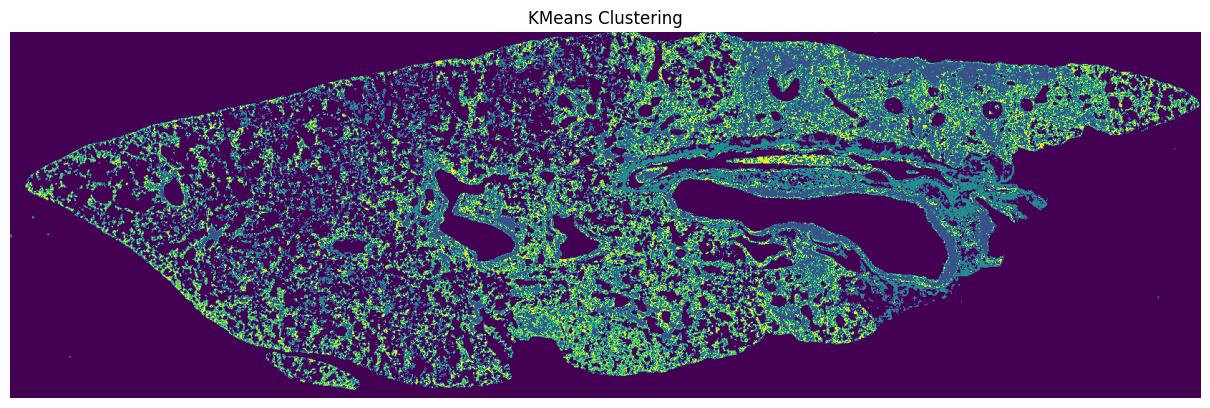

In [6]:
r2 = display_image(res2.cluster_labels, res2.original_shape[0], res2.original_shape[1], res2.mask, title='KMeans Clustering')